In [8]:
from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from astropy.time import Time
from astropy.coordinates import EarthLocation, AltAz, get_sun, SkyCoord
import numpy as np
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
import astropy.units as u
from astropy.coordinates import SkyCoord, EarthLocation
from astropy import time, coordinates as coord, units as u


In [9]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None, T0=None, P=None,D=None):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    
    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0 
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)
    
    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]
    
    # Observer location
    observer = EarthLocation.of_site(telescope_location)
    
    visible_transits = []

    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D
        
        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)
        
        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")
        
        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
        
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
        
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
        
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz
        
        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 3 and end_airmass < 3:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
    
    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")


In [10]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None, plot=False,T0=None, P=None,D=None):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    import matplotlib.pyplot as plt
    import numpy as np

    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0 
 
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd

    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]

    # Observer location
    observer = EarthLocation.of_site(telescope_location)

    visible_transits = []

    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D

        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)

        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)

        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)

        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt

        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 2.5 and end_airmass < 2.5:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))

    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")

   
    # Plotting
    if plot and visible_transits:
        for i, (start_transit, mid_transit, end_transit, mid_airmass) in enumerate(visible_transits):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit

            print(type(start_transit))  # Debugging type
            
            # Convert datetime to astropy Time
            start_time = Time(start_transit)  
            end_time = Time(end_transit)  
            
            # Compute baseline start and end if applicable
            if baseline_duration:
                baseline_start_time = start_time - baseline_duration * u.day
                baseline_end_time = end_time + baseline_duration * u.day
            else:
                baseline_start_time = start_time
                baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses, 
                    label=f"Transit {i+1} | {mid_transit.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_transit, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_transit, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_transit, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            # Plot baseline start and end if applicable
            if baseline_duration:
                baseline_start = baseline_start_time.datetime
                baseline_end = baseline_end_time.datetime

                plt.axvline(baseline_start, color='c', linestyle='--', label='Baseline Start' if i == 0 else "")
                plt.axvline(baseline_end, color='m', linestyle='--', label='Baseline End' if i == 0 else "")

            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately
    return 

In [11]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None, plot=False,T0=None, P=None,D=None):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    import matplotlib.pyplot as plt
    import numpy as np
        # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0 
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)
    
    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]
    
    # Observer location
    observer = EarthLocation.of_site(telescope_location)
    
    visible_transits = []
    
    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D
    
        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)
    
        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")
    
        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
    
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
    
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
    
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz
    
        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 3 and end_airmass < 3:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
    
    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")
    
    
    # Plotting
    if plot and visible_transits:
        for i, (start_transit, mid_transit, end_transit, mid_airmass) in enumerate(visible_transits):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit
    
            print(type(start_transit))  # Debugging type
            
            # Convert datetime to astropy Time
            start_time = Time(start_transit)  
            end_time = Time(end_transit)  
            
            # Compute baseline start and end if applicable
            if baseline_duration:
                baseline_start_time = start_time - baseline_duration * u.day
                baseline_end_time = end_time + baseline_duration * u.day
            else:
                baseline_start_time = start_time
                baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()
    
            plt.plot(datetime_array, airmasses, 
                    label=f"Transit {i+1} | {mid_transit.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_transit, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_transit, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_transit, color='b', linestyle='--', label='End of Transit' if i == 0 else "")
    
            # Plot baseline start and end if applicable
            if baseline_duration:
                baseline_start = baseline_start_time.datetime
                baseline_end = baseline_end_time.datetime
    
                plt.axvline(baseline_start, color='c', linestyle='--', label='Baseline Start' if i == 0 else "")
                plt.axvline(baseline_end, color='m', linestyle='--', label='Baseline End' if i == 0 else "")
    
            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately
    return start_times_utc, end_times_utc

In [12]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None, plot=False, T0=None, P=None, D=None):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    import matplotlib.pyplot as plt
    import numpy as np

    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0

    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd

    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]

    # Observer location
    observer = EarthLocation.of_site(telescope_location)

    visible_transits = []
    start_times_utc = []  # Initialize list for start times
    end_times_utc = []    # Initialize list for end times

    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D

        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)

        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)

        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)

        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt

        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 3 and end_airmass < 3:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
                start_times_utc.append(time_start.datetime)
                end_times_utc.append(time_end.datetime)

    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")

    # Plotting
    if plot and visible_transits:
        for i, (start_transit, mid_transit, end_transit, mid_airmass) in enumerate(visible_transits):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit

            # Convert datetime to astropy Time
            start_time = Time(start_transit)
            end_time = Time(end_transit)

            # Compute baseline start and end if applicable
            if baseline_duration:
                baseline_start_time = start_time - baseline_duration * u.day
                baseline_end_time = end_time + baseline_duration * u.day
            else:
                baseline_start_time = start_time
                baseline_end_time = end_time

            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end

            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness

            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)

            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses,
                     label=f"Transit {i+1} | {mid_transit.strftime('%Y-%m-%d %H:%M:%S')} UTC")

            # Plot vertical lines for transit events
            plt.axvline(start_transit, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_transit, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_transit, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            # Plot baseline start and end if applicable
            if baseline_duration:
                baseline_start = baseline_start_time.datetime
                baseline_end = baseline_end_time.datetime

                plt.axvline(baseline_start, color='c', linestyle='--', label='Baseline Start' if i == 0 else "")
                plt.axvline(baseline_end, color='m', linestyle='--', label='Baseline End' if i == 0 else "")

            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately

    return start_times_utc, end_times_utc

In [13]:
predict_transits("HD 189733 b", start_date="2027-01-01", end_date="2027-06-01",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=0/24, plot=False)#,T0=2458955.970923, P=1.48111874,D=3.9158/24)


/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),



Upcoming transits for HD 189733 b at Canada-France-Hawaii Telescope:
Transit 1: 2027-04-27 13:10:48 UTC | 2027-04-27 14:05:30 UTC | 2027-04-27 15:00:12 UTC | Airmass: 1.126
Transit 2: 2027-05-17 12:23:33 UTC | 2027-05-17 13:18:15 UTC | 2027-05-17 14:12:57 UTC | Airmass: 1.065
Transit 3: 2027-05-26 09:22:32 UTC | 2027-05-26 10:17:14 UTC | 2027-05-26 11:11:56 UTC | Airmass: 1.688


/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),


([datetime.datetime(2027, 4, 27, 13, 10, 48, 699224),
  datetime.datetime(2027, 5, 17, 12, 23, 33, 140233),
  datetime.datetime(2027, 5, 26, 9, 22, 32, 891757)],
 [datetime.datetime(2027, 4, 27, 15, 0, 12, 802747),
  datetime.datetime(2027, 5, 17, 14, 12, 57, 243756),
  datetime.datetime(2027, 5, 26, 11, 11, 56, 995279)])

In [14]:
def predict_emission(planet_name, start_date, end_date, telescope_location, phase, plot, additional_obs_hours, T0=None, P=None, D=None):
    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0  # Transit duration in days
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_phases = [T0 + (E * P) + (phase * P) for E in range(E_start, E_end + 1)]
    
    # Observer location
    observer = EarthLocation.of_site(telescope_location)

    visible_phases = []

    for phase_mid in future_phases:
        phase_start = phase_mid - (D / 2) - (additional_obs_hours / 24.0 / 2)
        phase_end = phase_mid + (D / 2) + (additional_obs_hours / 24.0 / 2)
        
        time_start = Time(phase_start, format='jd')
        time_mid = Time(phase_mid, format='jd')
        time_end = Time(phase_end, format='jd')

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
        
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
        
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_mid = get_sun(time_mid).transform_to(altaz_mid).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
    
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 2 and end_airmass < 2:
                visible_phases.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
    
    # Extract start and end times as separate arrays
    start_times_utc = [start_phase_utc for start_phase_utc, _, _, _ in visible_phases]
    end_times_utc = [end_phase_utc for _, _, end_phase_utc, _ in visible_phases]

    # Print results
    if visible_phases:
        print(f"\nUpcoming fully visible phase {phase} for {planet_name} at {telescope_location}:")
        for i, (start_phase_utc, mid_phase_utc, end_phase_utc, mid_airmass) in enumerate(visible_phases):
            print(f"Phase {i+1}: {start_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | {mid_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | {end_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Mid Airmass: {mid_airmass:.3f}")
    else:
        print("No fully visible phases found in the given date range.")

    # Plotting
    if plot and visible_phases:
        for i, (start_phase, mid_phase, end_phase, mid_airmass) in enumerate(visible_phases):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit

            # Convert datetime to astropy Time
            start_time = Time(start_phase)  
            end_time = Time(end_phase)  
            
            # Compute baseline start and end if applicable
            baseline_start_time = start_time
            baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses, 
                    label=f"Phase {i+1} | {mid_phase.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_phase, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_phase, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_phase, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately

    return start_times_utc, end_times_utc

In [15]:
def predict_emission(planet_name, start_date, end_date, telescope_location, phase, plot, additional_obs_hours, T0=None, P=None, D=None):
    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    
    if T0 is None:
        T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    if P is None:
        P = table["pl_orbper"][0].value  # Orbital period
    if D is None:
        D = table["pl_trandur"][0].value / 24.0  # Transit duration in days
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_phases = [T0 + (E * P) + (phase * P) for E in range(E_start, E_end + 1)]
    
    # Observer location
    observer = EarthLocation.of_site(telescope_location)

    visible_phases = []

    for phase_mid in future_phases:
        phase_start = phase_mid - (D / 2) - (additional_obs_hours / 24.0 / 2)
        phase_end = phase_mid + (D / 2) + (additional_obs_hours / 24.0 / 2)
        
        time_start = Time(phase_start, format='jd')
        time_mid = Time(phase_mid, format='jd')
        time_end = Time(phase_end, format='jd')

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
        
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
        
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
    
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 2 and end_airmass < 2:
                visible_phases.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
    
    # Print results
    if visible_phases:
        print(f"\nUpcoming fully visible phase {phase} for {planet_name} at {telescope_location}:")
        for i, (start_phase_utc, mid_phase_utc, end_phase_utc, mid_airmass) in enumerate(visible_phases):
            print(f"Phase {i+1}: {start_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | {mid_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | {end_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Mid Airmass: {mid_airmass:.3f}")
    else:
        print("No fully visible phases found in the given date range.")

    # Plotting
    if plot and visible_phases:
        for i, (start_phase, mid_phase, end_phase, mid_airmass) in enumerate(visible_phases):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit
            
            # Convert datetime to astropy Time
            start_time = Time(start_phase)  
            end_time = Time(end_phase)  
            
            # Compute baseline start and end if applicable
            baseline_start_time = start_time
            baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses, 
                    label=f"Phase {i+1} | {mid_phase.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_phase, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_phase, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_phase, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately

    # Return start and end times
    return [start for start, _, _, _ in visible_phases], [end for _, _, end, _ in visible_phases]


Upcoming fully visible phase 0.25 for WASP-33b at Canada-France-Hawaii Telescope:
Phase 1: 2025-09-27 09:19:54 UTC | 2025-09-27 12:15:31 UTC | 2025-09-27 15:11:09 UTC | Mid Airmass: 1.051
Phase 2: 2025-10-08 08:49:26 UTC | 2025-10-08 11:45:03 UTC | 2025-10-08 14:40:40 UTC | Mid Airmass: 1.051
Phase 3: 2025-10-19 08:18:57 UTC | 2025-10-19 11:14:35 UTC | 2025-10-19 14:10:12 UTC | Mid Airmass: 1.053
Phase 4: 2025-10-30 07:48:29 UTC | 2025-10-30 10:44:06 UTC | 2025-10-30 13:39:43 UTC | Mid Airmass: 1.058
Phase 5: 2025-11-10 07:18:01 UTC | 2025-11-10 10:13:38 UTC | 2025-11-10 13:09:15 UTC | Mid Airmass: 1.065
Phase 6: 2025-11-21 06:47:32 UTC | 2025-11-21 09:43:09 UTC | 2025-11-21 12:38:47 UTC | Mid Airmass: 1.075
Phase 7: 2025-12-02 06:17:04 UTC | 2025-12-02 09:12:41 UTC | 2025-12-02 12:08:18 UTC | Mid Airmass: 1.088
Phase 8: 2025-12-13 05:46:35 UTC | 2025-12-13 08:42:13 UTC | 2025-12-13 11:37:50 UTC | Mid Airmass: 1.104


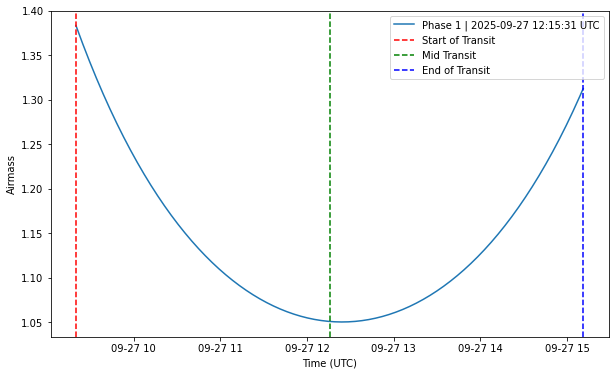

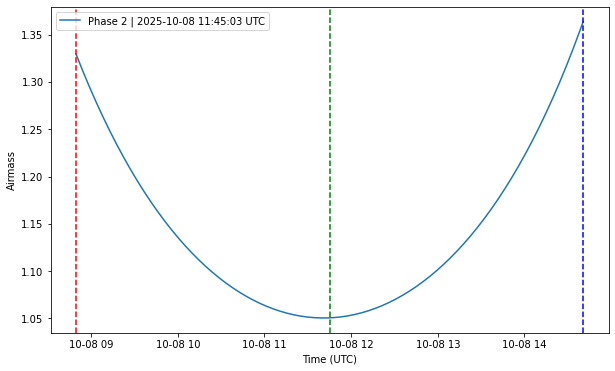

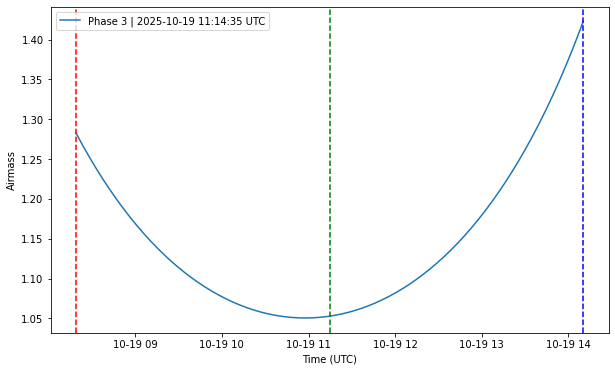

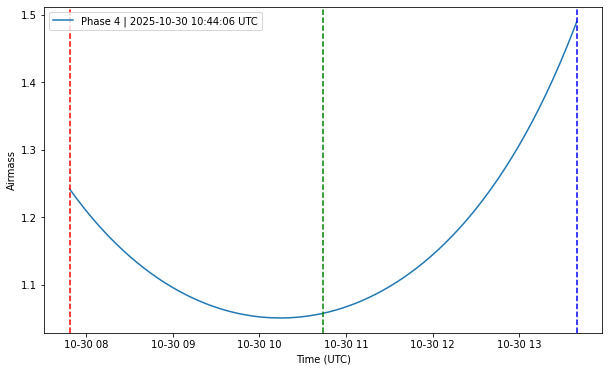

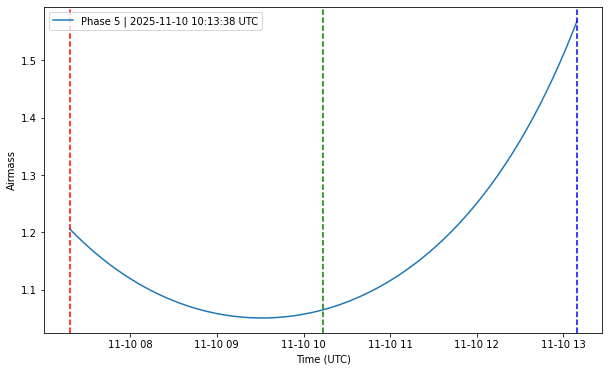

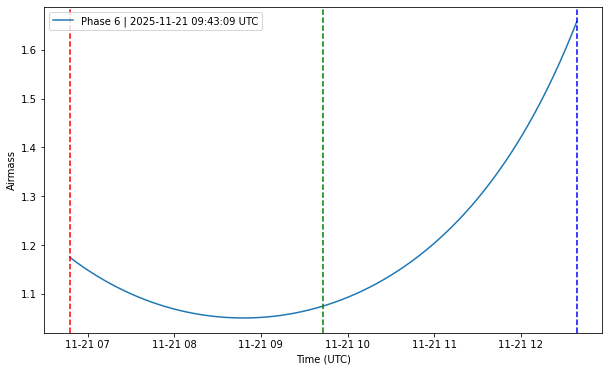

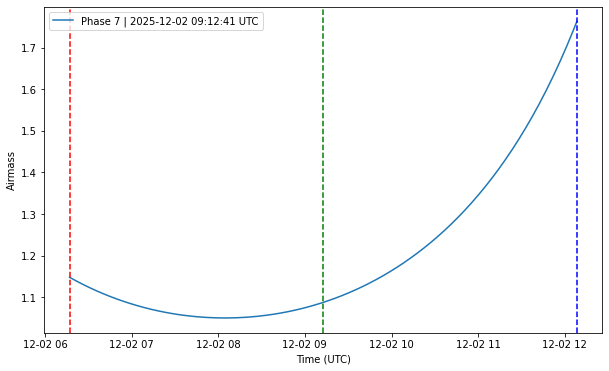

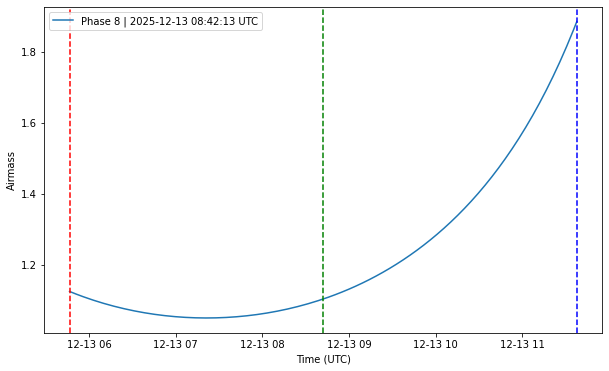


Upcoming fully visible phase 0.75 for WASP-33b at Canada-France-Hawaii Telescope:
Phase 1: 2025-10-05 07:37:54 UTC | 2025-10-05 10:33:31 UTC | 2025-10-05 13:29:08 UTC | Mid Airmass: 1.102
Phase 2: 2025-10-16 07:07:25 UTC | 2025-10-16 10:03:03 UTC | 2025-10-16 12:58:40 UTC | Mid Airmass: 1.086
Phase 3: 2025-10-27 06:36:57 UTC | 2025-10-27 09:32:34 UTC | 2025-10-27 12:28:11 UTC | Mid Airmass: 1.074
Phase 4: 2025-11-07 06:06:29 UTC | 2025-11-07 09:02:06 UTC | 2025-11-07 11:57:43 UTC | Mid Airmass: 1.064
Phase 5: 2025-11-18 05:36:00 UTC | 2025-11-18 08:31:37 UTC | 2025-11-18 11:27:15 UTC | Mid Airmass: 1.057
Phase 6: 2025-11-29 05:05:32 UTC | 2025-11-29 08:01:09 UTC | 2025-11-29 10:56:46 UTC | Mid Airmass: 1.052
Phase 7: 2025-12-10 04:35:03 UTC | 2025-12-10 07:30:41 UTC | 2025-12-10 10:26:18 UTC | Mid Airmass: 1.051


In [20]:
start_w33b_utc,end_w33b_utc=predict_emission("WASP-33b", start_date="2025-08-01", end_date="2026-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=3,plot=True,T0=2454163.22367, P=1.21987089,D=2.854/24)
start_w33b_utc,end_w33b_utc=predict_emission("WASP-33b", start_date="2025-08-01", end_date="2026-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=3,plot=False,T0=2454163.22367, P=1.21987089,D=2.854/24)


In [17]:
print(start_w33b_utc)

[datetime.datetime(2025, 10, 5, 7, 37, 54, 212837), datetime.datetime(2025, 10, 16, 7, 7, 25, 816880), datetime.datetime(2025, 10, 27, 6, 36, 57, 420964), datetime.datetime(2025, 11, 7, 6, 6, 29, 25007), datetime.datetime(2025, 11, 18, 5, 36, 0, 629091), datetime.datetime(2025, 11, 29, 5, 5, 32, 233134), datetime.datetime(2025, 12, 10, 4, 35, 3, 837217)]


In [18]:
import matplotlib.pyplot as plt
import calendar
from datetime import datetime, timedelta
import matplotlib.colors as mcolors
import numpy as np

def plot_calendar_with_segments(planets_data, start_year, end_year, white_days, include_extra_month=False):
    """
    Plots a multi-year calendar with segmented boxes for overlapping planet observations, with improved text visibility.
    Observations on unavailable (gray) days are not plotted.

    Parameters:
        planets_data (dict): Dictionary where keys are planet names and values are dictionaries of phases.
                             Each phase dictionary contains tuples of (start_times, end_times).
                             Example:
                             {
                                 "Planet A": {
                                     "N1": ([start_times], [end_times]),
                                     "D1": ([start_times], [end_times])
                                 }
                             }
        start_year (int): The starting year of the calendar.
        end_year (int): The ending year of the calendar.
        white_days (dict): Dictionary where keys are years, and values are dictionaries where keys are months (1-12)
                           and values are lists of days (1-31) that should remain white.
        include_extra_month (bool): If True, includes January of the year after `end_year`.
    """
    # Generate a unique color for each planet
    colors = list(mcolors.TABLEAU_COLORS.values())
    planet_colors = {planet: colors[i % len(colors)] for i, planet in enumerate(planets_data.keys())}

    # Create a dictionary to store observation days and labels for each date
    observation_days = {}
    for planet, phases in planets_data.items():
        for phase, (start_times, end_times) in phases.items():
            if len(start_times) != len(end_times):
                raise ValueError(f"start_times and end_times must have the same length for {planet} - {phase}.")
            for start, end in zip(start_times, end_times):
                date = start.date()
                year = date.year
                month = date.month
                day = date.day
                # Only add observations if the date is in the white days
                if year in white_days and month in white_days[year] and day in white_days[year][month]:
                    if date not in observation_days:
                        observation_days[date] = {}
                    if planet not in observation_days[date]:
                        observation_days[date][planet] = []
                    observation_days[date][planet].append(phase)

    # Determine the total number of months to plot
    total_months = (end_year - start_year + 1) * 12
    if include_extra_month:
        total_months += 1  # Add January of the year after `end_year`

    # Calculate the number of rows needed for the calendar grid
    num_rows = int(np.ceil(total_months / 3))  # 3 columns per row

    # Create a figure for the calendar
    fig, axes = plt.subplots(num_rows, 3, figsize=(30, 50))  # Taller figure size for better visibility
    axes = axes.flatten()  # Flatten the axes array for easier indexing
    fig.suptitle(f"Calendar from {start_year} to January {end_year + 1}", fontsize=32)

    # Iterate over years and months to create a grid of calendars
    month_idx = 0
    for year in range(start_year, end_year + 2 if include_extra_month else end_year + 1):
        for month in range(1, 13):
            if month_idx >= total_months:
                break  # Stop if we've plotted all months
            ax = axes[month_idx]
            ax.set_title(f"{calendar.month_name[month]} {year}", fontsize=20, pad=20)

            # Get the month's calendar as a matrix
            month_calendar = calendar.monthcalendar(year, month)

            # Plot the calendar grid
            for week_idx, week in enumerate(month_calendar):
                for day_idx, day in enumerate(week):
                    if day == 0:  # Empty days
                        continue
                    date = datetime(year, month, day).date()

                    # Check if the date is a white day
                    if year in white_days and month in white_days[year] and day in white_days[year][month]:
                        # Check if the date has observations
                        if date in observation_days:
                            # Get the number of planets with observations on this date
                            num_planets = len(observation_days[date])
                            segment_height = 1.0 / num_planets  # Divide the box into equal segments

                            # Draw a segment for each planet
                            for i, (planet, phases) in enumerate(observation_days[date].items()):
                                phase_labels = ", ".join(phases)  # Combine all phases for this planet
                                # Draw the segment
                                ax.add_patch(plt.Rectangle(
                                    (day_idx - 0.5, -week_idx - 0.5 + i * segment_height),  # Bottom-left corner
                                    1, segment_height,  # Width and height
                                    color=planet_colors[planet], edgecolor='black'
                                ))
                                # Add the phase label inside the segment
                                ax.text(day_idx, -week_idx - 0.5 + (i + 0.5) * segment_height, phase_labels,
                                        ha='center', va='center', fontsize=12, color='black', weight='bold')

                            # Add the day number at the top of the box
                            ax.text(day_idx, -week_idx, str(day), ha='center', va='top', fontsize=16, color='black', weight='bold')
                        else:
                            # Regular white days
                            ax.text(day_idx, -week_idx, str(day), ha='center', va='center', fontsize=16,
                                    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=1.5'))
                    else:
                        # Gray out unavailable days
                        ax.text(day_idx, -week_idx, str(day), ha='center', va='center', fontsize=16,
                                bbox=dict(facecolor='lightgray', edgecolor='black', boxstyle='round,pad=1.5'))

            # Set limits and remove axes
            ax.set_xlim(-0.5, 6.5)
            ax.set_ylim(-len(month_calendar) + 0.5, 0.5)
            ax.axis('off')

            month_idx += 1

    # Add a legend for the planets
    handles = [plt.Line2D([0], [0], color=color, marker='o', linestyle='', markersize=12, label=planet)
               for planet, color in planet_colors.items()]
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=20, frameon=True, framealpha=1.0, edgecolor='black')

    # Adjust layout and show the plot
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # Adjust layout to make space for the legend
    plt.show()



In [19]:
#WASP-33b
start_w33b_quad_25,end_w33b_quad_25=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_w33b_quad_75,end_w33b_quad_27=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_w33b_NS_1,end_w33b_NS_1=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.865,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_w33b_NS_2,end_w33b_NS_2=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.135,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_w33b_DS_1,end_w33b_DS_1=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.415,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_w33b_DS_2,end_w33b_DS_2=predict_emission("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.585,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_w33b_TR,end_w33b_TR=predict_transits("WASP-33b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False)

#Kelt 9b
start_K9_quad_25,end_K9_quad_25=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)
start_K9_quad_75,end_K9_quad_27=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)

start_K9_NS_1,end_K9_NS_1=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.88,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)
start_K9_NS_2,end_K9_NS_2=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.125,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)

start_K9_DS_1,end_K9_DS_1=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.405,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)
start_K9_DS_2,end_K9_DS_2=predict_emission("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.595,additional_obs_hours=0,plot=False,T0=2458955.970923, P=None,D=None)

start_K9_TR,end_K9_TR=predict_transits("KELT-9b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False,T0=2458955.970923)


#Wasp 189b
start_W189b_quad_25,end_W189b_quad_25=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)
start_W189b_quad_75,end_W189b_quad_27=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)

start_W189b_NS_1,end_W189b_NS_1=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.9,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)
start_W189b_NS_2,end_W189b_NS_2=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.1,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)

start_W189b_DS_1,end_W189b_DS_1=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.435,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)
start_W189b_DS_2,end_W189b_DS_2=predict_emission("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.565,additional_obs_hours=0,plot=False,T0=2458926.5416960, P=None,D=None)

start_W189b_TR,end_W189b_TR=predict_transits("WASP-189b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False,T0=2458926.5416960)

#WASP 76b
start_W76b_quad_25,end_W76b_quad_25=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_W76b_quad_75,end_W76b_quad_27=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_W76b_NS_1,end_W76b_NS_1=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.885,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_W76b_NS_2,end_W76b_NS_2=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.115,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_W76b_DS_1,end_W76b_DS_1=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.425,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_W76b_DS_2,end_W76b_DS_2=predict_emission("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.575,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_W76b_TR,end_W76b_TR=predict_transits("WASP-76b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False)

#HD 189733b
start_HD189b_quad_25,end_HD189b_quad_25=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD189b_quad_75,end_HD189b_quad_27=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD189b_NS_1,end_HD189b_NS_1=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.9,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD189b_NS_2,end_HD189b_NS_2=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.1,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD189b_DS_1,end_HD189b_DS_1=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.45,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD189b_DS_2,end_HD189b_DS_2=predict_emission("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.55,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD189b_TR,end_HD189b_TR=predict_transits("HD 189733b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False)

#HD 209458b
start_HD209b_quad_25,end_HD209b_quad_25=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.25,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD209b_quad_75,end_HD209b_quad_27=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.75,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD209b_NS_1,end_HD209b_NS_1=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.9,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD209b_NS_2,end_HD209b_NS_2=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.1,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD209b_DS_1,end_HD209b_DS_1=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.455,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)
start_HD209b_DS_2,end_HD209b_DS_2=predict_emission("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope', phase=0.545,additional_obs_hours=0,plot=False,T0=None, P=None,D=None)

start_HD209b_TR,end_HD209b_TR=predict_transits("HD 209458b", start_date="2025-03-01", end_date="2027-01-31",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=2/24, plot=False)


/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year 


Upcoming fully visible phase 0.25 for WASP-33b at Canada-France-Hawaii Telescope:
Phase 1: 2025-08-25 12:21:00 UTC | 2025-08-25 13:46:36 UTC | 2025-08-25 15:12:13 UTC | Mid Airmass: 1.068
Phase 2: 2025-09-05 11:50:31 UTC | 2025-09-05 13:16:07 UTC | 2025-09-05 14:41:44 UTC | Mid Airmass: 1.060
Phase 3: 2025-09-16 11:20:02 UTC | 2025-09-16 12:45:38 UTC | 2025-09-16 14:11:14 UTC | Mid Airmass: 1.054
Phase 4: 2025-09-21 08:26:29 UTC | 2025-09-21 09:52:05 UTC | 2025-09-21 11:17:42 UTC | Mid Airmass: 1.347
Phase 5: 2025-09-27 10:49:32 UTC | 2025-09-27 12:15:09 UTC | 2025-09-27 13:40:45 UTC | Mid Airmass: 1.051
Phase 6: 2025-10-02 07:55:59 UTC | 2025-10-02 09:21:36 UTC | 2025-10-02 10:47:12 UTC | Mid Airmass: 1.298
Phase 7: 2025-10-08 10:19:03 UTC | 2025-10-08 11:44:40 UTC | 2025-10-08 13:10:16 UTC | Mid Airmass: 1.051
Phase 8: 2025-10-13 07:25:30 UTC | 2025-10-13 08:51:07 UTC | 2025-10-13 10:16:43 UTC | Mid Airmass: 1.255
Phase 9: 2025-10-19 09:48:34 UTC | 2025-10-19 11:14:11 UTC | 2025-10-

/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year 


Upcoming fully visible phase 0.75 for WASP-33b at Canada-France-Hawaii Telescope:
Phase 1: 2025-07-31 12:10:26 UTC | 2025-07-31 13:36:02 UTC | 2025-07-31 15:01:39 UTC | Mid Airmass: 1.274
Phase 2: 2025-08-11 11:39:57 UTC | 2025-08-11 13:05:33 UTC | 2025-08-11 14:31:10 UTC | Mid Airmass: 1.234
Phase 3: 2025-08-22 11:09:28 UTC | 2025-08-22 12:35:04 UTC | 2025-08-22 14:00:41 UTC | Mid Airmass: 1.200
Phase 4: 2025-09-02 10:38:59 UTC | 2025-09-02 12:04:35 UTC | 2025-09-02 13:30:12 UTC | Mid Airmass: 1.169
Phase 5: 2025-09-13 10:08:30 UTC | 2025-09-13 11:34:06 UTC | 2025-09-13 12:59:43 UTC | Mid Airmass: 1.143
Phase 6: 2025-09-24 09:38:01 UTC | 2025-09-24 11:03:37 UTC | 2025-09-24 12:29:13 UTC | Mid Airmass: 1.121
Phase 7: 2025-09-30 12:01:04 UTC | 2025-09-30 13:26:41 UTC | 2025-09-30 14:52:17 UTC | Mid Airmass: 1.095
Phase 8: 2025-10-05 09:07:31 UTC | 2025-10-05 10:33:08 UTC | 2025-10-05 11:58:44 UTC | Mid Airmass: 1.102
Phase 9: 2025-10-11 11:30:35 UTC | 2025-10-11 12:56:12 UTC | 2025-10-

/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year 

...

/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),



Upcoming fully visible phase 0.25 for WASP-76b at Canada-France-Hawaii Telescope:
Phase 1: 2025-09-09 10:39:06 UTC | 2025-09-09 12:33:06 UTC | 2025-09-09 14:27:06 UTC | Mid Airmass: 1.050
Phase 2: 2025-09-29 08:27:38 UTC | 2025-09-29 10:21:38 UTC | 2025-09-29 12:15:38 UTC | Mid Airmass: 1.102
Phase 3: 2025-10-08 09:38:47 UTC | 2025-10-08 11:32:47 UTC | 2025-10-08 13:26:47 UTC | Mid Airmass: 1.056
Phase 4: 2025-10-28 07:27:19 UTC | 2025-10-28 09:21:19 UTC | 2025-10-28 11:15:19 UTC | Mid Airmass: 1.050
Phase 5: 2025-11-06 08:38:28 UTC | 2025-11-06 10:32:28 UTC | 2025-11-06 12:26:28 UTC | Mid Airmass: 1.123
Phase 6: 2025-11-17 05:15:50 UTC | 2025-11-17 07:09:50 UTC | 2025-11-17 09:03:50 UTC | Mid Airmass: 1.101
Phase 7: 2025-11-26 06:26:59 UTC | 2025-11-26 08:20:59 UTC | 2025-11-26 10:14:59 UTC | Mid Airmass: 1.057
Phase 8: 2025-12-25 05:26:40 UTC | 2025-12-25 07:20:40 UTC | 2025-12-25 09:14:40 UTC | Mid Airmass: 1.125
Phase 9: 2026-09-06 10:05:06 UTC | 2026-09-06 11:59:06 UTC | 2026-09-

/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "utcut1" yielded 1 of "dubious year (Note 3)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warnings.warn('ERFA function "{}" yielded {}'.format(func_name, wmsg),
/Users/ronaldmraz/.local/lib/python3.9/site-packages/erfa/core.py:154: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year 


Upcoming fully visible phase 0.75 for WASP-76b at Canada-France-Hawaii Telescope:
Phase 1: 2025-08-21 10:33:41 UTC | 2025-08-21 12:27:41 UTC | 2025-08-21 14:21:41 UTC | Mid Airmass: 1.156
Phase 2: 2025-09-19 09:33:22 UTC | 2025-09-19 11:27:22 UTC | 2025-09-19 13:21:22 UTC | Mid Airmass: 1.069
Phase 3: 2025-09-28 10:44:31 UTC | 2025-09-28 12:38:31 UTC | 2025-09-28 14:32:31 UTC | Mid Airmass: 1.081
Phase 4: 2025-10-09 07:21:54 UTC | 2025-10-09 09:15:54 UTC | 2025-10-09 11:09:54 UTC | Mid Airmass: 1.154
Phase 5: 2025-10-18 08:33:03 UTC | 2025-10-18 10:27:03 UTC | 2025-10-18 12:21:03 UTC | Mid Airmass: 1.046
Phase 6: 2025-10-27 09:44:12 UTC | 2025-10-27 11:38:12 UTC | 2025-10-27 13:32:12 UTC | Mid Airmass: 1.184
Phase 7: 2025-11-07 06:21:34 UTC | 2025-11-07 08:15:34 UTC | 2025-11-07 10:09:34 UTC | Mid Airmass: 1.068
Phase 8: 2025-11-16 07:32:43 UTC | 2025-11-16 09:26:43 UTC | 2025-11-16 11:20:43 UTC | Mid Airmass: 1.082
Phase 9: 2025-12-06 05:21:15 UTC | 2025-12-06 07:15:15 UTC | 2025-12-

KeyboardInterrupt: 

In [95]:
import matplotlib.pyplot as plt
import calendar
from datetime import datetime, timedelta
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd  # Import pandas for Excel export

def plot_calendar_with_segments(planets_data, start_year, end_year, white_days, include_extra_month=False, output_excel_path="observations.xlsx"):
    """
    Plots a multi-year calendar with segmented boxes for overlapping planet observations, with improved text visibility.
    Observations on unavailable (gray) days are not plotted. Also generates an Excel sheet with observation times.

    Parameters:
        planets_data (dict): Dictionary where keys are planet names and values are dictionaries of phases.
                             Each phase dictionary contains tuples of (start_times, end_times).
                             Example:
                             {
                                 "Planet A": {
                                     "N1": ([start_times], [end_times]),
                                     "D1": ([start_times], [end_times])
                                 }
                             }
        start_year (int): The starting year of the calendar.
        end_year (int): The ending year of the calendar.
        white_days (dict): Dictionary where keys are years, and values are dictionaries where keys are months (1-12)
                           and values are lists of days (1-31) that should remain white.
        include_extra_month (bool): If True, includes January of the year after `end_year`.
        output_excel_path (str): Path to save the Excel file with observation times.
    """
    # Generate a unique color for each planet
    colors = list(mcolors.TABLEAU_COLORS.values())
    planet_colors = {planet: colors[i % len(colors)] for i, planet in enumerate(planets_data.keys())}

    # Create a dictionary to store observation days and labels for each date
    observation_days = {}
    observation_records = []  # List to store observation records for Excel export
    for planet, phases in planets_data.items():
        for phase, (start_times, end_times) in phases.items():
            if len(start_times) != len(end_times):
                raise ValueError(f"start_times and end_times must have the same length for {planet} - {phase}.")
            for start, end in zip(start_times, end_times):
                date = start.date()
                year = date.year
                month = date.month
                day = date.day
                # Only add observations if the date is in the white days
                if year in white_days and month in white_days[year] and day in white_days[year][month]:
                    if date not in observation_days:
                        observation_days[date] = {}
                    if planet not in observation_days[date]:
                        observation_days[date][planet] = []
                    observation_days[date][planet].append(phase)
                    # Add record for Excel export
                    observation_records.append({
                        "Planet": planet,
                        "Phase": phase,
                        "Start Time": start,
                        "End Time": end
                    })

    # Export observation records to an Excel file
    df = pd.DataFrame(observation_records)
    df.sort_values(by=["Start Time"], inplace=True)  # Sort by start time
    df.to_excel(output_excel_path, index=False)
    print(f"Observation times saved to {output_excel_path}")

    # Determine the total number of months to plot
    total_months = (end_year - start_year + 1) * 12
    if include_extra_month:
        total_months += 1  # Add January of the year after `end_year`

    # Calculate the number of rows needed for the calendar grid
    num_rows = int(np.ceil(total_months / 3))  # 3 columns per row

    # Create a figure for the calendar
    fig, axes = plt.subplots(num_rows, 3, figsize=(30, 50))  # Taller figure size for better visibility
    axes = axes.flatten()  # Flatten the axes array for easier indexing
    fig.suptitle(f"Calendar from {start_year} to January {end_year + 1}", fontsize=32)

    # Iterate over years and months to create a grid of calendars
    month_idx = 0
    for year in range(start_year, end_year + 2 if include_extra_month else end_year + 1):
        for month in range(1, 13):
            if month_idx >= total_months:
                break  # Stop if we've plotted all months
            ax = axes[month_idx]
            ax.set_title(f"{calendar.month_name[month]} {year}", fontsize=20, pad=20)

            # Get the month's calendar as a matrix
            month_calendar = calendar.monthcalendar(year, month)

            # Plot the calendar grid
            for week_idx, week in enumerate(month_calendar):
                for day_idx, day in enumerate(week):
                    if day == 0:  # Empty days
                        continue
                    date = datetime(year, month, day).date()

                    # Check if the date is a white day
                    if year in white_days and month in white_days[year] and day in white_days[year][month]:
                        # Check if the date has observations
                        if date in observation_days:
                            # Get the number of planets with observations on this date
                            num_planets = len(observation_days[date])
                            segment_height = 1.0 / num_planets  # Divide the box into equal segments

                            # Draw a segment for each planet
                            for i, (planet, phases) in enumerate(observation_days[date].items()):
                                phase_labels = ", ".join(phases)  # Combine all phases for this planet
                                # Draw the segment
                                ax.add_patch(plt.Rectangle(
                                    (day_idx - 0.5, -week_idx - 0.5 + i * segment_height),  # Bottom-left corner
                                    1, segment_height,  # Width and height
                                    color=planet_colors[planet], edgecolor='black'
                                ))
                                # Add the phase label inside the segment
                                ax.text(day_idx, -week_idx - 0.5 + (i + 0.5) * segment_height, phase_labels,
                                        ha='center', va='center', fontsize=12, color='black', weight='bold')

                            # Add the day number at the top of the box
                            ax.text(day_idx, -week_idx, str(day), ha='center', va='top', fontsize=16, color='black', weight='bold')
                        else:
                            # Regular white days
                            ax.text(day_idx, -week_idx, str(day), ha='center', va='center', fontsize=16,
                                    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=1.5'))
                    else:
                        # Gray out unavailable days
                        ax.text(day_idx, -week_idx, str(day), ha='center', va='center', fontsize=16,
                                bbox=dict(facecolor='lightgray', edgecolor='black', boxstyle='round,pad=1.5'))

            # Set limits and remove axes
            ax.set_xlim(-0.5, 6.5)
            ax.set_ylim(-len(month_calendar) + 0.5, 0.5)
            ax.axis('off')

            month_idx += 1

    # Add a legend for the planets
    handles = [plt.Line2D([0], [0], color=color, marker='o', linestyle='', markersize=12, label=planet)
               for planet, color in planet_colors.items()]
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=20, frameon=True, framealpha=1.0, edgecolor='black')

    # Adjust layout and show the plot
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # Adjust layout to make space for the legend
    plt.show()

Observation times saved to observations.xlsx


/var/folders/h4/0wskt2390pb0wdv_2_zby2900000gn/T/ipykernel_38066/688333551.py:64: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.1' currently installed).
  df.to_excel(output_excel_path, index=False)
/var/folders/h4/0wskt2390pb0wdv_2_zby2900000gn/T/ipykernel_38066/688333551.py:111: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle(


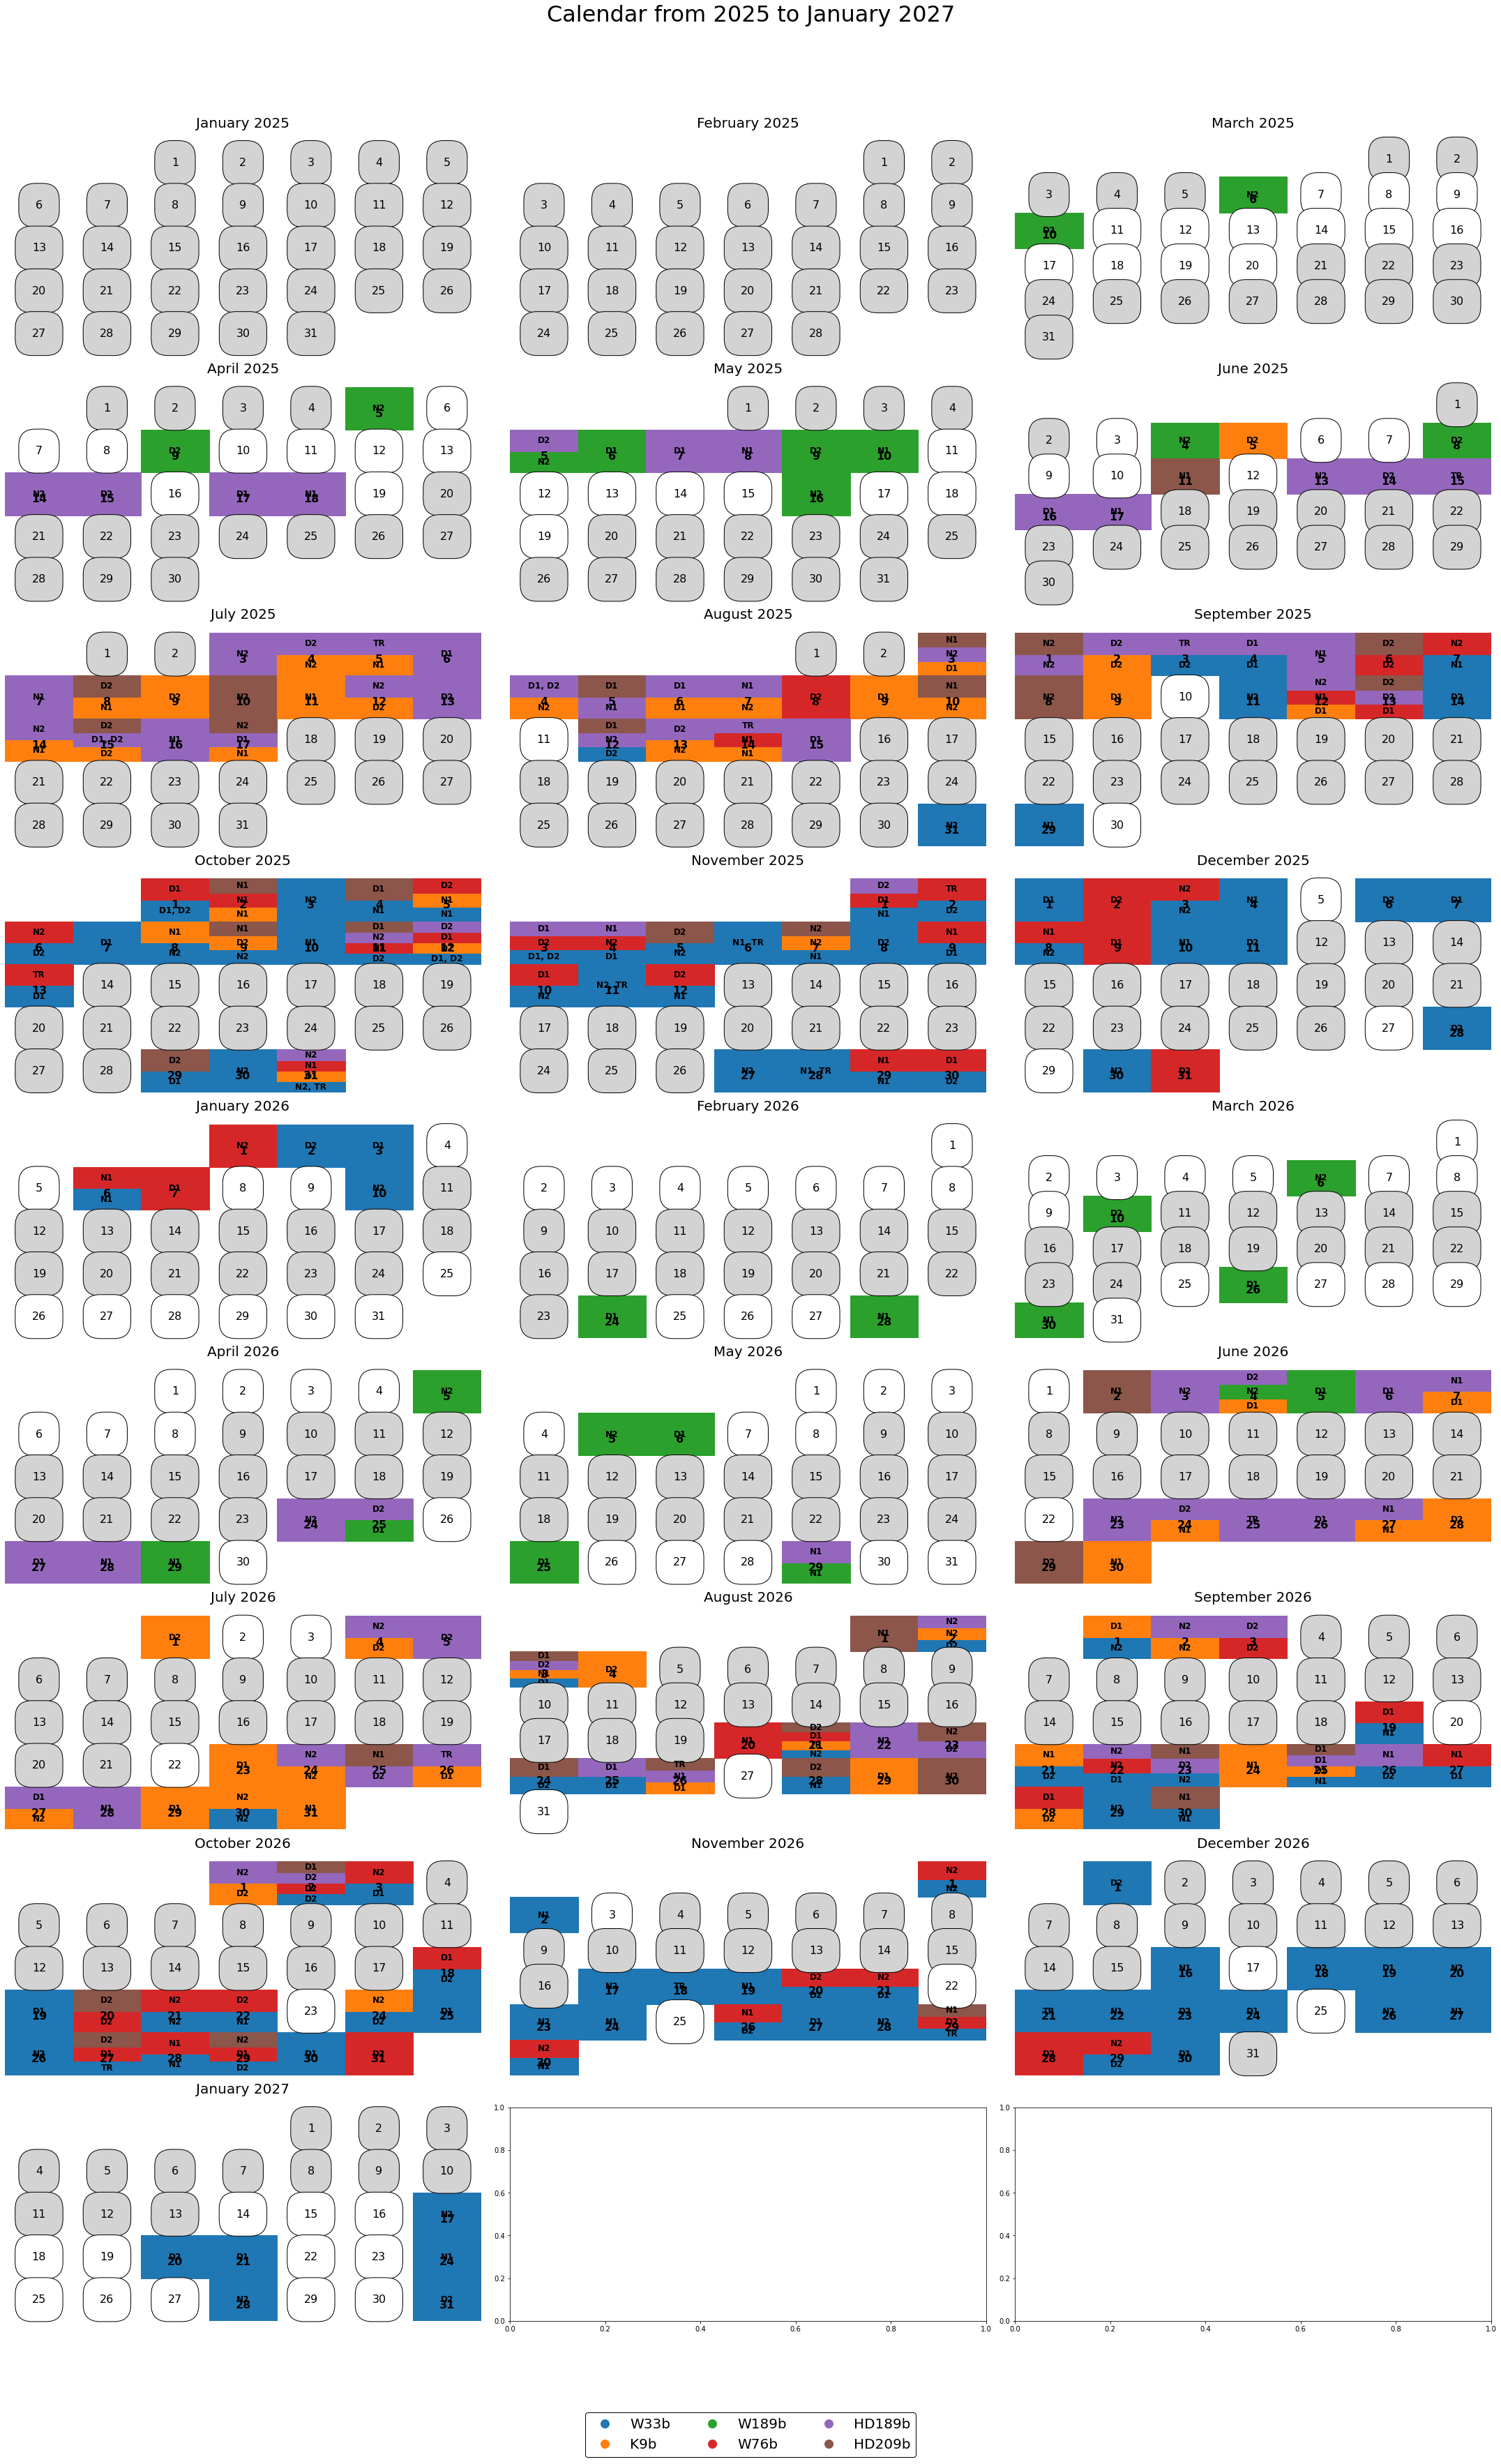

In [98]:
# Example usage
if __name__ == "__main__":
    # Example data for multiple planets and phases
    planets_data = {
        "W33b": {
            "N1": (
                start_w33b_NS_1,
                end_w33b_NS_1
            ),
            "N2": (
                start_w33b_NS_2,
                end_w33b_NS_2
            ),           
            "D1": (
                start_w33b_DS_1,
                end_w33b_DS_1
            ),
            "D2": (
                start_w33b_DS_2,
                end_w33b_DS_2
            ),    
            "TR": (
                start_w33b_TR,
                end_w33b_TR
            )          
        },
        "K9b": {
            "N1": (
                start_K9_NS_1,
                end_K9_NS_1
            ),
            "N2": (
                start_K9_NS_2,
                end_K9_NS_2
            ),           
            "D1": (
                start_K9_DS_1,
                end_K9_DS_1
            ),
            "D2": (
                start_K9_DS_2,
                end_K9_DS_2
            ), 
            "TR": (
                start_K9_TR,
                end_K9_TR
            )          
        },
        "W189b": {
            "N1": (
                start_W189b_NS_1,
                end_W189b_NS_1
            ),
            "N2": (
                start_W189b_NS_2,
                end_W189b_NS_2
            ),           
            "D1": (
                start_W189b_DS_1,
                end_W189b_DS_1
            ),
            "D2": (
                start_W189b_DS_2,
                end_W189b_DS_2
            ),           
            "TR": (
                start_W189b_TR,
                end_W189b_TR
            )         
        },
        "W76b": {
            "N1": (
                start_W76b_NS_1,
                end_W76b_NS_1
            ),
            "N2": (
                start_W76b_NS_2,
                end_W76b_NS_2
            ),           
            "D1": (
                start_W76b_DS_1,
                end_W76b_DS_1
            ),
            "D2": (
                start_W76b_DS_2,
                end_W76b_DS_2
            ),    
            "TR": (
                start_W76b_TR,
                end_W76b_TR
            )                
        },
        "HD189b": {
            "N1": (
                start_HD189b_NS_1,
                end_HD189b_NS_1
            ),
            "N2": (
                start_HD189b_NS_2,
                end_HD189b_NS_2
            ),           
            "D1": (
                start_HD189b_DS_1,
                end_HD189b_DS_1
            ),
            "D2": (
                start_HD189b_DS_2,
                end_HD189b_DS_2
            ),           
            "TR": (
                start_HD189b_TR,
                end_HD189b_TR
            )         
        },
        "HD209b": {
            "N1": (
                start_HD209b_NS_1,
                end_HD209b_NS_1
            ),
            "N2": (
                start_HD209b_NS_2,
                end_HD209b_NS_2
            ),           
            "D1": (
                start_HD209b_DS_1,
                end_HD209b_DS_1
            ),
            "D2": (
                start_HD209b_DS_2,
                end_HD209b_DS_2
            ),        
            "TR": (
                start_HD209b_TR,
                end_HD209b_TR
            )            
        },
    }
         
  
    # White days for 2025, 2026, and January 2027
    white_days = {
        2025: {
            3: list(range(6, 21)),  # March 6-20
            4: list(range(5, 20)),  # April 5-19
            5: list(range(5, 20)),  # May 5-19
            6: list(range(3, 18)),  # June 3-17
            7: list(range(3, 18)),  # July 3-17
            8: list(range(3, 16)) + [31],  # August 3-15 and 31
            9: list(range(1, 15)) + [29, 30],  # September 1-14 and 29-30
            10: list(range(1, 14)) + [29, 30, 31],  # October 1-13 and 29-31
            11: list(range(1, 13)) + [27, 28, 29, 30],  # November 1-12 and 27-30
            12: list(range(1, 12)) + [27, 28, 29, 30, 31]  # December 1-11 and 27-31
        },
        2026: {
            1: list(range(1, 11)) + list(range(25, 32)),  # January 1-10 and 25-31
            2: list(range(1, 9)) + list(range(24, 29)),  # February 1-8 and 24-28
            3: list(range(1, 11)) + list(range(25, 32)),  # March 1-10 and 25-31
            4: list(range(1, 9)) + list(range(24, 31)),  # April 1-8 and 24-30
            5: list(range(1, 9)) + list(range(25, 32)),  # May 1-8 and 25-31
            6: list(range(1, 8)) + list(range(22, 31)),  # June 1-7 and 22-30
            7: list(range(1, 6)) + list(range(22, 32)),  # July 1-5 and 22-31
            8: list(range(1, 5)) + list(range(20, 32)),  # August 1-4 and 20-31
            9: list(range(1, 4)) + list(range(19, 31)),  # September 1-3 and 19-30
            10: list(range(1, 4)) + list(range(18, 32)),  # October 1-3 and 18-31
            11: list(range(1, 4)) + list(range(17, 32)),  # November 1-3 and 17-31
            12: [1] + list(range(16, 31))  # December 1 and 16-30
        },
        2027: {
            1: list(range(14, 32))  # January 14-31
        }
    }

    plot_calendar_with_segments(planets_data, 2025, 2026, white_days, include_extra_month=True)